# Logistic Regression — Student Dropout
Người thực hiện: **Huỳnh Lê Khánh Ly**. Dùng development.csv; chưa đánh giá test.

Baseline học máy theo proposal.

Chạy từng cell từ trên xuống. Đóng Excel trước khi chạy. Dùng học kỳ 2 nên không gọi đây là dự đoán lúc nhập học.

## 1. Đọc dữ liệu và cố định thực nghiệm

### Thông tin thực nghiệm và thư viện

In [10]:
OWNER = 'Huỳnh Lê Khánh Ly'
OWNER_ID = 'ly'
MODEL_NAME = 'Logistic Regression'
SCALE_NUMERIC = True
from pathlib import Path
from datetime import datetime
import hashlib, json, platform, uuid, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, recall_score, classification_report, ConfusionMatrixDisplay

### Đọc và kiểm tra dữ liệu development

In [12]:
project_dir = Path.cwd().resolve()
if project_dir.name == 'notebooks':
    project_dir = project_dir.parent
data_path = project_dir / 'data' / 'processed' / 'development.csv'
if not data_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {data_path}. Chạy bước chia dữ liệu trong 01_eda.ipynb trước.')
data = pd.read_csv(data_path)
data.columns = [' '.join(c.split()) for c in data.columns]
assert not data.columns.duplicated().any()
assert data.isna().sum().sum() == 0, 'Phát hiện missing: cần kiểm tra lại.'
X = data.drop(columns='Target')
label_names = ['Dropout', 'Enrolled', 'Graduate']
label_mapping = {label: i for i, label in enumerate(label_names)}
assert set(data['Target'].unique()) == set(label_names)
y = data['Target'].map(label_mapping).astype(int)
print('Mã nhãn:', label_mapping)


Mã nhãn: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


### Thiết lập nhãn, cross-validation và metrics

In [13]:
DATA_HASH = hashlib.sha256(data_path.read_bytes()).hexdigest()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X, y))
scoring = {
    'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'weighted_f1': 'f1_weighted',
    'recall_dropout': make_scorer(recall_score, labels=[0], average='macro', zero_division=0)
}

### Tạo thư mục lưu kết quả

In [16]:
experiment_dir = project_dir / 'experiments' / OWNER_ID
figure_dir = project_dir / 'report' / 'figures' / OWNER_ID
model_dir = project_dir / 'models' / OWNER_ID
for directory in [experiment_dir, figure_dir, model_dir]:
    directory.mkdir(parents=True, exist_ok=True)
print('Người thực hiện:', OWNER)
print('X:', X.shape, '| y:', y.shape)
print('SHA256 dữ liệu:', DATA_HASH)
print('Không đọc test.csv. CV chỉ chạy trên development.csv.')


Người thực hiện: Huỳnh Lê Khánh Ly
X: (3539, 36) | y: (3539,)
SHA256 dữ liệu: dfe524288135ecf474ab9b9cf03277f19b818b879cafc176a571aa2a9dbaa690
Không đọc test.csv. CV chỉ chạy trên development.csv.


## 2. Xây dựng tiền xử lý

### Phân nhóm đặc trưng và kiểm tra

In [14]:
categorical_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
numeric_cols = ['Application order', 'Previous qualification (grade)', 'Admission grade',
    'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP'] + [
    f'Curricular units {semester} sem ({measure})'
    for semester in ['1st', '2nd'] for measure in [
        'credited', 'enrolled', 'evaluations', 'approved', 'grade', 'without evaluations']]
assigned = categorical_cols + binary_cols + numeric_cols
assert len(assigned) == len(set(assigned)) == 36
assert set(assigned) == set(X.columns)
for col in binary_cols:
    assert set(X[col].unique()) <= {0, 1}, col


### Hàm xây dựng pipeline tiền xử lý

In [6]:
def build_pipeline(estimator):
    processor = ColumnTransformer([
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numeric', StandardScaler() if SCALE_NUMERIC else 'passthrough', numeric_cols),
        ('binary', 'passthrough', binary_cols)
    ])
    return Pipeline([('preprocessing', processor), ('model', estimator)])

print('Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.')


Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.


## 3. Hàm đánh giá và nhật ký Excel

### Hàm ghi nhật ký Excel

In [7]:
log_path = experiment_dir / 'experiment_history.xlsx'

def save_log(row):
    # Đóng Excel trước khi chạy để tránh PermissionError trên Windows.
    frame = pd.DataFrame([row])
    if log_path.exists():
        old = pd.read_excel(log_path, sheet_name='Runs')
        frame = pd.concat([old, frame], ignore_index=True)
    frame.to_excel(log_path, sheet_name='Runs', index=False, engine='openpyxl')
    print('Đã ghi Excel:', log_path)


### Hàm đánh giá cross-validation

In [8]:
results = []
def run_cv(estimator, name, note):
    run_id = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
    scores = cross_validate(estimator, X, y, cv=folds, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score='raise')
    details = pd.DataFrame({k: v for k, v in scores.items()})
    details.insert(0, 'fold', range(1, 6))
    details.to_csv(experiment_dir / f'{run_id}_folds.csv', index=False)
    row = {
        'Run_ID': run_id, 'Timestamp': datetime.now().isoformat(timespec='seconds'),
        'Run_By': OWNER, 'Model': name, 'Stage': 'CV fixed configuration',
        'Data_SHA256': DATA_HASH, 'Samples': len(y),
        'Split': 'development 80%; StratifiedKFold 5; shuffle=True; seed=42',
        'Parameters': json.dumps(estimator.get_params(deep=False), default=str, ensure_ascii=False),
        'Preprocessing': 'OneHot categorical; binary passthrough; numeric ' + ('StandardScaler' if SCALE_NUMERIC else 'passthrough'),
        'Train_Macro_F1': scores['train_macro_f1'].mean(),
        'CV_Macro_F1': scores['test_macro_f1'].mean(),
        'CV_Macro_F1_STD': scores['test_macro_f1'].std(ddof=1),
        'CV_Accuracy': scores['test_accuracy'].mean(),
        'CV_Weighted_F1': scores['test_weighted_f1'].mean(),
        'CV_Recall_Dropout': scores['test_recall_dropout'].mean(),
        'Mean_Fit_Seconds': scores['fit_time'].mean(),
        'Python': platform.python_version(), 'sklearn': sklearn.__version__,
        'Note': note
    }
    save_log(row)
    results.append(row)
    display(pd.DataFrame([row])[['Model', 'Train_Macro_F1', 'CV_Macro_F1', 'CV_Macro_F1_STD', 'CV_Accuracy', 'CV_Recall_Dropout']])
    return scores


## 4. Baseline Dummy

In [9]:
dummy_scores = run_cv(DummyClassifier(strategy='most_frequent'), 'Dummy most frequent', 'Baseline; ignores input features.')

Đã ghi Excel: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\ly\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Dummy most frequent,0.222013,0.222013,0.000209,0.499294,0.0


## 5. Mô hình ban đầu

### Khởi tạo Logistic Regression và không gian tham số

In [2]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=3000, solver="lbfgs", C=1.0)
param_grid = {"model__C": [0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]}

### Đánh giá cấu hình ban đầu

In [11]:
initial_scores = run_cv(build_pipeline(model), MODEL_NAME + ' initial', 'Fixed initial configuration before tuning.')

Đã ghi Excel: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\ly\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Logistic Regression initial,0.754686,0.701321,0.015078,0.776204,0.772162


### Nhận xét
Logistic Regression đạt CV Macro-F1 là 0,7013, cao hơn đáng kể so với Dummy (0,2220). Accuracy đạt 77,62% và Recall của lớp Dropout đạt 77,22%, cho thấy mô hình đã học được thông tin từ các đặc trưng.

Tuy nhiên, Train Macro-F1 là 0,7547, cao hơn CV khoảng 0,0534, cho thấy vẫn có chênh lệch giữa kết quả trên tập huấn luyện và tập validation. Cần tiếp tục tinh chỉnh siêu tham số và phân tích lỗi theo từng lớp.

## 6. Tinh chỉnh siêu tham số

### Chạy GridSearchCV và xuất bảng kết quả

In [12]:
search = GridSearchCV(build_pipeline(model), param_grid=param_grid,
    scoring='f1_macro', cv=folds, refit=True, n_jobs=1,
    return_train_score=True, error_score='raise')
started = time.perf_counter()
search.fit(X, y)
elapsed = time.perf_counter() - started
search_id = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
search_table = pd.DataFrame(search.cv_results_)
search_table.to_csv(experiment_dir / f'{search_id}_grid_search.csv', index=False)


### Ghi từng cấu hình tuning vào nhật ký Excel

In [13]:
# Ghi mọi cấu hình đã thử, không chỉ cấu hình thắng.
existing = pd.read_excel(log_path, sheet_name='Runs') if log_path.exists() else pd.DataFrame()
tuning_rows = []
for i, params in enumerate(search.cv_results_['params']):
    tuning_rows.append({
        'Run_ID': f'{search_id}_candidate_{i+1}',
        'Timestamp': datetime.now().isoformat(timespec='seconds'), 'Run_By': OWNER,
        'Model': MODEL_NAME, 'Stage': 'GridSearchCV candidate',
        'Data_SHA256': DATA_HASH, 'Samples': len(y),
        'Split': 'Same development; same 5 folds; seed=42',
        'Parameters': json.dumps(params, ensure_ascii=False),
        'Preprocessing': 'OneHot; binary passthrough; numeric ' + ('StandardScaler' if SCALE_NUMERIC else 'passthrough'),
        'Train_Macro_F1': search.cv_results_['mean_train_score'][i],
        'CV_Macro_F1': search.cv_results_['mean_test_score'][i],
        'CV_Macro_F1_STD': search.cv_results_['std_test_score'][i],
        'Mean_Fit_Seconds': search.cv_results_['mean_fit_time'][i],
        'Python': platform.python_version(), 'sklearn': sklearn.__version__,
        'Note': 'Điểm dùng chọn tham số; không phải đánh giá test độc lập.'
    })
pd.concat([existing, pd.DataFrame(tuning_rows)], ignore_index=True).to_excel(
    log_path, sheet_name='Runs', index=False, engine='openpyxl')


### Hiển thị kết quả tuning

In [14]:
print('Tham số tốt nhất:', search.best_params_)
print('CV Macro-F1 tốt nhất (điểm lựa chọn):', round(search.best_score_, 4))
print('Số cấu hình:', len(tuning_rows), '| Thời gian:', round(elapsed, 2), 'giây')
print('Đã lưu mọi cấu hình vào Excel:', log_path)
display(search_table[['params', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score'))

print('Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.')


Tham số tốt nhất: {'model__C': 0.1, 'model__class_weight': 'balanced'}
CV Macro-F1 tốt nhất (điểm lựa chọn): 0.7174
Số cấu hình: 6 | Thời gian: 9.97 giây
Đã lưu mọi cấu hình vào Excel: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\ly\experiment_history.xlsx


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.751526,0.717353,0.018191,1
3,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.767002,0.709537,0.014515,2
5,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.771436,0.704442,0.014503,3
2,"{'model__C': 1.0, 'model__class_weight': None}",0.754686,0.701321,0.013486,4
4,"{'model__C': 10.0, 'model__class_weight': None}",0.762821,0.694884,0.010569,5
0,"{'model__C': 0.1, 'model__class_weight': None}",0.724294,0.694601,0.018160,6


Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.


## Nhận xét
GridSearchCV đã thử nghiệm 6 cấu hình siêu tham số và lựa chọn cấu hình tốt nhất với C = 0.1 và class_weight = 'balanced'.

CV Macro-F1 tốt nhất đạt 0,7174, tăng khoảng 0,0160 so với mô hình ban đầu (0,7013). Điều này cho thấy quá trình tuning đã giúp cải thiện hiệu quả phân loại của Logistic Regression.

Tuy nhiên, đây mới là kết quả đánh giá bằng cross-validation trên tập development, chưa phải kết quả đánh giá độc lập trên tập test.

## 7. Phân tích lỗi và so sánh baseline

### Dự đoán out-of-fold và báo cáo phân loại

In [15]:
# OOF cho cấu hình ban đầu, chưa được chọn bằng tuning.
# Mỗi mẫu được dự đoán bởi mô hình không fit trên mẫu đó.
oof_pred = cross_val_predict(build_pipeline(model), X, y, cv=folds, n_jobs=1)
labels = [0, 1, 2]
report = classification_report(y, oof_pred, labels=labels, target_names=label_names, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
pd.DataFrame(report).T.to_csv(experiment_dir / 'initial_model_oof_report.csv', encoding='utf-8-sig')


,precision,recall,f1-score,support
Dropout,0.8011,0.7722,0.7864,1137.0000
Enrolled,0.5786,0.3827,0.4607,635.0000
Graduate,0.8038,0.9202,0.8580,1767.0000
accuracy,0.7762,0.7762,0.7762,0.7762
macro avg,0.7278,0.6917,0.7017,3539.0000
weighted avg,0.7625,0.7762,0.7637,3539.0000


### Vẽ ma trận nhầm lẫn

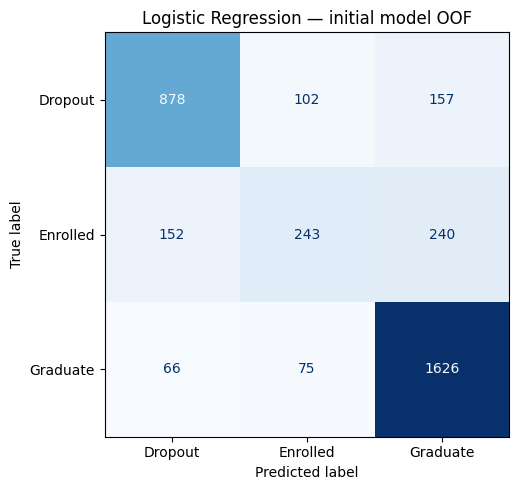

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, oof_pred, labels=labels, display_labels=label_names, ax=ax, cmap='Blues', colorbar=False)
ax.set_title(MODEL_NAME + ' — initial model OOF')
fig.tight_layout()
fig.savefig(figure_dir / 'initial_model_oof_confusion.png', dpi=200)
plt.show()
plt.close(fig)


### So sánh với baseline

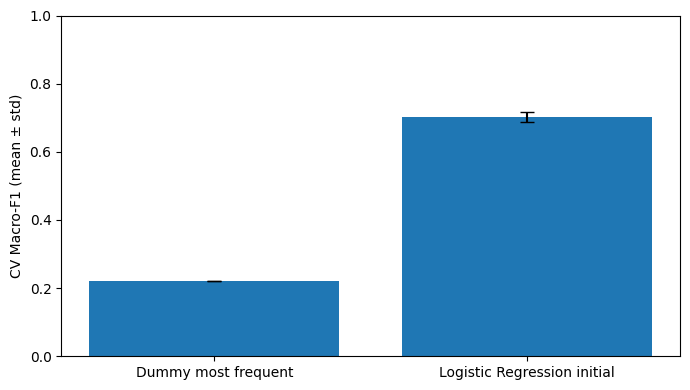

In [17]:
comparison = pd.DataFrame(results).set_index('Model')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(comparison.index, comparison['CV_Macro_F1'], yerr=comparison['CV_Macro_F1_STD'], capsize=5)
ax.set_ylim(0, 1)
ax.set_ylabel('CV Macro-F1 (mean ± std)')
fig.tight_layout()
fig.savefig(figure_dir / 'baseline_comparison.png', dpi=200)
plt.show()
plt.close(fig)


### Nhận xét
Kết quả OOF của mô hình Logistic Regression ban đầu cho thấy khả năng nhận diện giữa các lớp còn chênh lệch.

Graduate có Recall cao nhất (92,02%).

Dropout đạt Recall 77,22%.

Enrolled có Recall thấp nhất (38,27%).

Điều này cho thấy mô hình nhận diện lớp Graduate tương đối tốt nhưng vẫn gặp khó khăn với lớp Enrolled. Một số sinh viên thuộc lớp Enrolled có thể bị dự đoán nhầm sang các lớp khác.

OOF Macro-F1 đạt 0,7017. Vì vậy, cần tiếp tục phân tích ma trận nhầm lẫn và so sánh kết quả trước – sau tuning để xác định mức độ cải thiện của mô hình.

## 8. Lưu pipeline ứng viên

### Lưu pipeline ứng viên

In [18]:
import joblib
# GridSearchCV đã refit cấu hình tốt nhất trên toàn bộ development.
# Đây là mô hình ứng viên; chưa xác nhận chất lượng trên test.
model_path = model_dir / 'candidate_pipeline.joblib'
joblib.dump(search.best_estimator_, model_path)


['C:\\doan\\sgu-MAYHOC\\ML01_Student_Dropout\\models\\ly\\candidate_pipeline.joblib']

### Lưu metadata và thông báo kết quả

In [19]:
metadata = {
    'owner': OWNER, 'model': MODEL_NAME, 'data_sha256': DATA_HASH,
    'best_params': search.best_params_, 'selection_cv_macro_f1': search.best_score_,
    'test_evaluated': False, 'sklearn': sklearn.__version__,
    'label_mapping': label_mapping, 'feature_columns': X.columns.tolist()
}
(model_dir / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu pipeline ứng viên:', model_path)
print('Nhật ký Excel:', log_path)
print('Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.')


Đã lưu pipeline ứng viên: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\models\ly\candidate_pipeline.joblib
Nhật ký Excel: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\ly\experiment_history.xlsx
Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.


## Phân tích lỗi OOF sau tinh chỉnh

In [4]:
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import cross_val_predict

,precision,recall,f1-score,support
Dropout,0.8340,0.7335,0.7805,1137.0
Enrolled,0.4640,0.6189,0.5304,635.0
Graduate,0.8599,0.8234,0.8413,1767.0


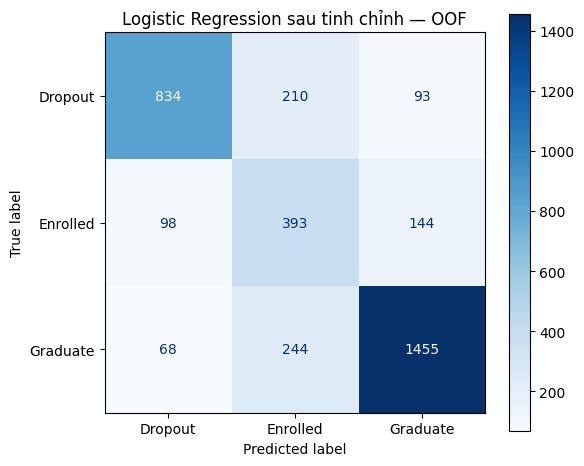

In [17]:
tuned_params = {"C": 0.1, "class_weight": "balanced"}
tuned_model = clone(model).set_params(**tuned_params)
tuned_pipeline = build_pipeline(tuned_model)

tuned_oof_pred = cross_val_predict(
    tuned_pipeline, X, y, cv=folds, n_jobs=1
)

labels = [label_mapping[name] for name in label_names]
report = classification_report(
    y, tuned_oof_pred,
    labels=labels,
    target_names=label_names,
    output_dict=True,
    zero_division=0,
)
tuned_report_df = pd.DataFrame(report).T
display(tuned_report_df.loc[label_names].round(4))
tuned_report_df.to_csv(
    experiment_dir / "tuned_model_oof_report.csv", encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y, tuned_oof_pred,
    labels=labels,
    display_labels=label_names,
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set_title("Logistic Regression sau tinh chỉnh — OOF")
fig.tight_layout()
fig.savefig(figure_dir / "tuned_model_oof_confusion.png", dpi=150)
plt.show()

### Nhận xét kết quả phân tích lỗi sau tinh chỉnh

Kết quả dự đoán ngoài phần huấn luyện cho thấy Logistic Regression sau tinh chỉnh nhận diện đúng 834/1.137 mẫu Dropout (Recall 73,35%), 393/635 mẫu Enrolled (Recall 61,89%) và 1.455/1.767 mẫu Graduate (Recall 82,34%).

So với mô hình ban đầu, Recall của lớp Enrolled tăng từ 38,27% lên 61,89%, tương ứng tăng 23,62 điểm phần trăm. Tuy nhiên, Recall của lớp Dropout giảm từ 77,22% xuống 73,35%, còn lớp Graduate giảm từ 92,02% xuống 82,34%.

Kết quả cho thấy việc tinh chỉnh với C = 0.1 và class_weight = 'balanced' giúp cải thiện đáng kể khả năng nhận diện lớp Enrolled, nhưng đồng thời làm giảm khả năng nhận diện hai lớp còn lại. Điều này phản ánh sự đánh đổi về hiệu quả phân loại giữa các lớp khi sử dụng trọng số cân bằng.

Mặc dù CV Macro-F1 tăng từ 0,7013 lên 0,7174 sau tinh chỉnh, mô hình vẫn còn nhầm lẫn đáng kể giữa các trạng thái, đặc biệt là Enrolled và Graduate. Vì vậy, cần xem xét đồng thời Macro-F1 và Recall của từng lớp khi đánh giá chất lượng mô hình.

Các kết quả trên được tính trên tập phát triển thông qua dự đoán OOF, chưa phải kết quả đánh giá trên tập kiểm tra cuối cùng.

## 9. Nhật ký tiến độ cá nhân



| Ngày | Công việc | Kết quả | Khó khăn | Bước tiếp theo |
|---|---|---|---|---|
| 04/11/2026 | Xây dựng và đánh giá Logistic Regression ban đầu | CV Macro-F1 đạt 0,7013; Accuracy đạt 77,62% | Kết quả giữa các lớp còn chênh lệch, đặc biệt lớp Enrolled | Tinh chỉnh siêu tham số |
| 04/11/2026 | Tinh chỉnh Logistic Regression bằng GridSearchCV | C = 0.1, class_weight = balanced; CV Macro-F1 đạt 0,7174 | Mức cải thiện Macro-F1 chưa lớn | Phân tích lỗi OOF |
| 04/11/2026 | Phân tích lỗi OOF của Logistic Regression ban đầu | Recall Graduate 92,02%; Dropout 77,22%; Enrolled 38,27% | Mô hình nhận diện lớp Enrolled còn kém | So sánh kết quả trước và sau tuning |
| 07/11/2026 | Phân tích lỗi OOF của Logistic Regression sau tinh chỉnh và so sánh với mô hình ban đầu | Recall Dropout 73,35%; Enrolled 61,89%; Graduate 82,34%. Recall Enrolled tăng 23,62 điểm phần trăm so với ban đầu | Recall của Dropout và Graduate giảm; vẫn còn nhầm lẫn giữa các lớp | Tổng hợp kết quả trước/sau tinh chỉnh, cập nhật báo cáo và chuẩn bị so sánh với các mô hình khác |
